# Question 6: Customer Churn Prediction
**Task:** Supervised Machine Learning – Binary Classification  
**Target Variable:** `churn` (0 = Retained, 1 = Churned)  
**Input Features:** `tenure`, `monthly_charges`, `total_charges`, `contract_type`, `tech_tickets`  

### Marks Rubric (40 Marks):
1. **Section 1: EDA [10 Marks]** — Dataset creation, inspection, and class balance check
2. **Section 2: Technique Implementation [10 Marks]** — Preprocessing & Baseline Decision Tree Classifier
3. **Section 3: Evaluate Model [10 Marks]** — Confusion Matrix, Accuracy, Precision, Recall, F1-Score
4. **Section 4: Modify Technique Based on Requirement [10 Marks]** — Random Forest Classifier with Hyperparameter Tuning (GridSearchCV)

In [1]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

plt.rcParams['figure.figsize'] = (8, 4)
print("Libraries imported successfully!")

Libraries imported successfully!


## Section 1: Exploratory Data Analysis (EDA) [10 Marks]

In [2]:
# 1.1 Simple Exam-Friendly Dataset Generation (500 customers)
np.random.seed(42)
n = 500

tenure = np.random.randint(1, 60, n)                     # Months
monthly_charges = np.random.uniform(20, 110, n)         # Monthly fee ($)
total_charges = tenure * monthly_charges + np.random.normal(0, 20, n)
contract_type = np.random.choice([0, 1, 2], n, p=[0.5, 0.3, 0.2]) # 0: Month-to-month, 1: One year, 2: Two year
tech_tickets = np.random.randint(0, 6, n)               # Support tickets

# Churn logit
score = -0.05 * tenure + 0.02 * monthly_charges - 1.2 * contract_type + 0.4 * tech_tickets
prob = 1 / (1 + np.exp(-score))
churn = (prob > 0.50).astype(int)

df = pd.DataFrame({
    'tenure': tenure,
    'monthly_charges': np.round(monthly_charges, 1),
    'total_charges': np.round(total_charges, 1),
    'contract_type': contract_type,
    'tech_tickets': tech_tickets,
    'churn': churn
})

print("Dataset created! Shape:", df.shape)
df.head()

Dataset created! Shape: (500, 6)


,tenure,monthly_charges,total_charges,contract_type,tech_tickets,churn
0,39,28.5,1088.7,1,3,0
1,52,72.0,3736.1,2,0,0
2,29,23.2,677.2,1,2,0
3,15,61.9,945.3,0,3,1
4,43,68.8,2942.2,2,2,0


In [3]:
# 1.2 Inspection & Missing Values
print("=== Dataset Info ===")
df.info()
print("\n=== Missing Values ===")
print(df.isnull().sum())
print("\n=== Churn Class Balance ===")
print(df['churn'].value_counts())

=== Dataset Info ===
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   tenure           500 non-null    int64  
 1   monthly_charges  500 non-null    float64
 2   total_charges    500 non-null    float64
 3   contract_type    500 non-null    int64  
 4   tech_tickets     500 non-null    int64  
 5   churn            500 non-null    int64  
dtypes: float64(2), int64(4)
memory usage: 23.6 KB

=== Missing Values ===
tenure             0
monthly_charges    0
total_charges      0
contract_type      0
tech_tickets       0
churn              0
dtype: int64

=== Churn Class Balance ===
churn
0    259
1    241
Name: count, dtype: int64


/var/folders/hm/g9cgxswn4jd9nz_kd3zhpr100000gn/T/ipykernel_23460/774131761.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['Month-to-Month (0)', 'One-Year (1)', 'Two-Year (2)'])
/var/folders/hm/g9cgxswn4jd9nz_kd3zhpr100000gn/T/ipykernel_23460/774131761.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='churn', y='tenure', data=df, ax=axes[1], palette=['lightgreen', 'salmon'])
/var/folders/hm/g9cgxswn4jd9nz_kd3zhpr100000gn/T/ipykernel_23460/774131761.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(['Retained (0)', 'Churned (1)'])


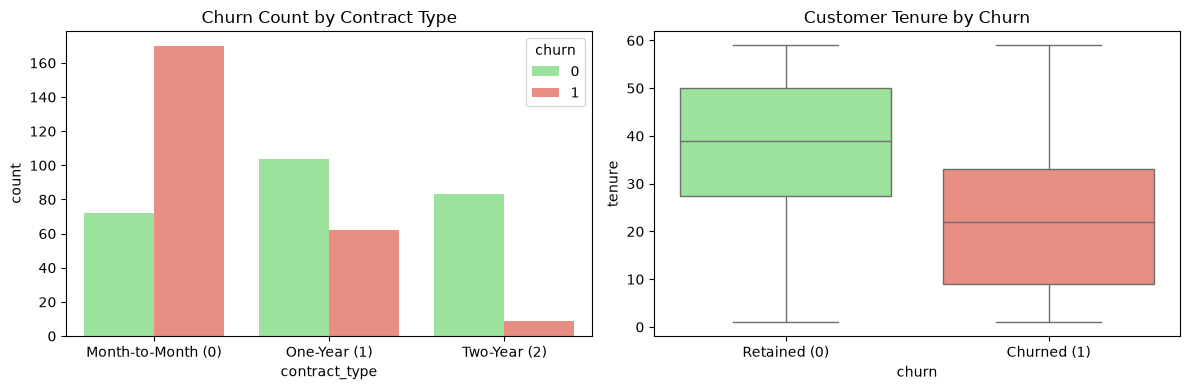

In [4]:
# 1.3 EDA Visualizations
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(x='contract_type', hue='churn', data=df, ax=axes[0], palette=['lightgreen', 'salmon'])
axes[0].set_xticklabels(['Month-to-Month (0)', 'One-Year (1)', 'Two-Year (2)'])
axes[0].set_title("Churn Count by Contract Type")

sns.boxplot(x='churn', y='tenure', data=df, ax=axes[1], palette=['lightgreen', 'salmon'])
axes[1].set_xticklabels(['Retained (0)', 'Churned (1)'])
axes[1].set_title("Customer Tenure by Churn")

plt.tight_layout()
plt.show()

## Section 2: Supervised Technique Implementation [10 Marks]

In [5]:
# 2.1 Feature-Target Split and Stratified Train-Test Split (80-20)
X = df.drop(columns=['churn'])
y = df['churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")

X_train: (400, 5), X_test: (100, 5)


In [6]:
# 2.2 Baseline Model: Decision Tree Classifier (max_depth=3)
dt = DecisionTreeClassifier(max_depth=3, random_state=42)
dt.fit(X_train_scaled, y_train)

y_pred_dt = dt.predict(X_test_scaled)
print("Baseline Decision Tree trained successfully!")

Baseline Decision Tree trained successfully!


## Section 3: Model Evaluation [10 Marks]

,Model,Accuracy,Precision,Recall,F1-Score
0,Baseline Decision Tree (depth=3),0.8,0.7414,0.8958,0.8113


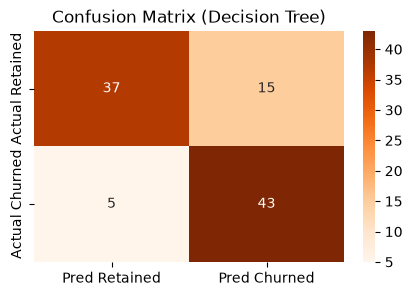


Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.71      0.79        52
           1       0.74      0.90      0.81        48

    accuracy                           0.80       100
   macro avg       0.81      0.80      0.80       100
weighted avg       0.81      0.80      0.80       100



In [7]:
# 3.1 Quantitative Metrics & Confusion Matrix
acc_dt = accuracy_score(y_test, y_pred_dt)
prec_dt = precision_score(y_test, y_pred_dt)
rec_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)

results_dt = {
    'Model': 'Baseline Decision Tree (depth=3)',
    'Accuracy': round(acc_dt, 4),
    'Precision': round(prec_dt, 4),
    'Recall': round(rec_dt, 4),
    'F1-Score': round(f1_dt, 4)
}
display(pd.DataFrame([results_dt]))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_dt)
plt.figure(figsize=(5, 3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', xticklabels=['Pred Retained', 'Pred Churned'], yticklabels=['Actual Retained', 'Actual Churned'])
plt.title("Confusion Matrix (Decision Tree)")
plt.show()

print("\nClassification Report:\n", classification_report(y_test, y_pred_dt))

## Section 4: Modify Technique Based on Requirement [10 Marks]
**Modifications Applied (from Lab 8 & Lab 10):**
1. **Ensemble Model:** `RandomForestClassifier` to reduce tree variance and improve generalization.
2. **Hyperparameter Tuning:** `GridSearchCV` on `n_estimators` and `max_depth`.
3. **Feature Importance:** Ranking the key drivers of customer churn.

In [8]:
# 4.1 Hyperparameter Tuning: Random Forest Classifier (GridSearchCV)
param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [3, 5, 8]
}

grid_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=5, scoring='f1')
grid_rf.fit(X_train, y_train)
best_rf = grid_rf.best_estimator_

y_pred_rf = best_rf.predict(X_test)

results_rf = {
    'Model': f"Tuned Random Forest {grid_rf.best_params_}",
    'Accuracy': round(accuracy_score(y_test, y_pred_rf), 4),
    'Precision': round(precision_score(y_test, y_pred_rf), 4),
    'Recall': round(recall_score(y_test, y_pred_rf), 4),
    'F1-Score': round(f1_score(y_test, y_pred_rf), 4)
}

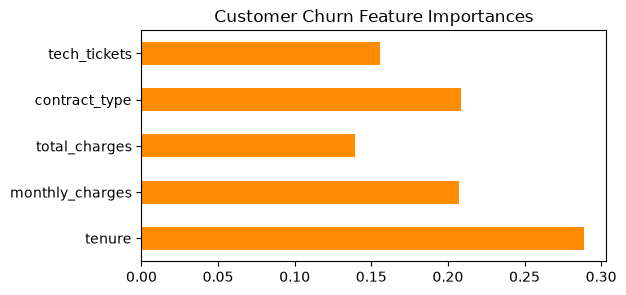

=== Final Model Comparison Table ===


,Model,Accuracy,Precision,Recall,F1-Score
0,Baseline Decision Tree (depth=3),0.80,0.7414,0.8958,0.8113
1,"Tuned Random Forest {'max_depth': 8, 'n_estima...",0.92,0.9167,0.9167,0.9167


In [9]:
# 4.2 Feature Importance & Comparison Table
fig, ax = plt.subplots(figsize=(6, 3))
feat_importances = pd.Series(best_rf.feature_importances_, index=X.columns)
feat_importances.plot(kind='barh', color='darkorange', ax=ax)
ax.set_title("Customer Churn Feature Importances")
plt.show()

comparison_df = pd.DataFrame([results_dt, results_rf])
print("=== Final Model Comparison Table ===")
display(comparison_df)